In [2]:
"""
Unstructured Text Analysis & Automated Triage with TF-IDF
Course: Data Science Tools & Techniques

Instructions:
Complete each TODO section below. You can run this file interactively cell-by-cell
in VS Code / PyCharm / Spyder (using the `# %%` markers) or directly via terminal:
    python lab15_starter.py
"""


# ## Setup & Dataset Loading

# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Download required NLTK resources quietly
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

# Load 4 real-world unstructured user discussion categories
CATEGORIES = [
    "sci.electronics",
    "rec.autos",
    "comp.sys.mac.hardware",
    "sci.med",
]

print("Loading dataset...")
raw_data = fetch_20newsgroups(
    subset="all",
    categories=CATEGORIES,
    remove=("headers", "footers", "quotes"),
)

df = pd.DataFrame(
    {
        "text": raw_data.data,
        "true_label": [raw_data.target_names[i] for i in raw_data.target],
    }
)

# Keep posts with meaningful length (> 50 characters)
df = df[df["text"].str.strip().str.len() > 50].reset_index(drop=True)
print(f"Loaded {len(df)} unstructured user posts.\n")


# %% [markdown]
# ## Step 1: Text Cleaning, Tokenization & Normalization (10 mins)

# %%
sample_post = df["text"].iloc[0][:400]
print("--- Raw Sample Post ---")
print(sample_post)
print("-" * 40)


Loading dataset...
Loaded 3703 unstructured user posts.

--- Raw Sample Post ---

My Honda has a cable release that can be locked out with the ignition key.
The valet key can be left with someone and will NOT unlock the trunk
or enable the cable release.
----------------------------------------


In [8]:
# Get a sample post
sample_post = df["text"].iloc[0][:400]

print("--- Raw Sample Post ---")
print(sample_post)
print("-" * 40)

# TODO 1.1: Tokenize and lowercase
tokens = [
    w.lower()
    for w in word_tokenize(sample_post)
    if w.isalpha()
]

# TODO 1.2: Remove stopwords
stop_words = set(stopwords.words("english"))

filtered_tokens = [
    w for w in tokens
    if w not in stop_words
]

# TODO 1.3: Stem and lemmatize
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_tokens = [
    stemmer.stem(w) for w in filtered_tokens
]

lemmatized_tokens = [
    lemmatizer.lemmatize(w, pos="v")
    for w in filtered_tokens
]

# Display results
print("Filtered Tokens:  ", filtered_tokens[:12])
print("Stemmed Roots:    ", stemmed_tokens[:12])
print("Lemmatized Words: ", lemmatized_tokens[:12])

--- Raw Sample Post ---

My Honda has a cable release that can be locked out with the ignition key.
The valet key can be left with someone and will NOT unlock the trunk
or enable the cable release.
----------------------------------------
Filtered Tokens:   ['honda', 'cable', 'release', 'locked', 'ignition', 'key', 'valet', 'key', 'left', 'someone', 'unlock', 'trunk']
Stemmed Roots:     ['honda', 'cabl', 'releas', 'lock', 'ignit', 'key', 'valet', 'key', 'left', 'someon', 'unlock', 'trunk']
Lemmatized Words:  ['honda', 'cable', 'release', 'lock', 'ignition', 'key', 'valet', 'key', 'leave', 'someone', 'unlock', 'trunk']


TF-IDF sparsity: 99.04%


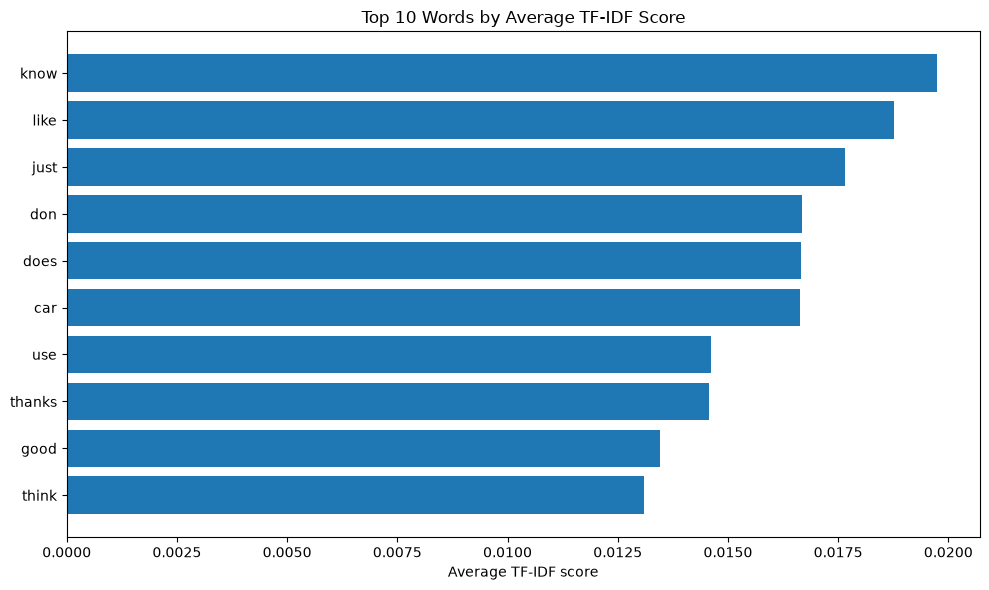

BoW shape: (3703, 4000)
TF-IDF shape: (3703, 4000)


In [9]:
# TODO 2.1: Create the vectorizers
bow_vec = CountVectorizer(
    stop_words="english",
    max_features=4000,
    min_df=5
)

tfidf_vec = TfidfVectorizer(
    stop_words="english",
    max_features=4000,
    min_df=5
)

# TODO 2.2: Transform the posts
X_bow = bow_vec.fit_transform(df["text"])
X_tfidf = tfidf_vec.fit_transform(df["text"])

# Percentage of zero entries in the TF-IDF matrix
total_entries = X_tfidf.shape[0] * X_tfidf.shape[1]
zero_entries = total_entries - X_tfidf.nnz
sparsity = (zero_entries / total_entries) * 100

print(f"TF-IDF sparsity: {sparsity:.2f}%")

# Average TF-IDF score for each feature
feature_names = tfidf_vec.get_feature_names_out()
average_scores = np.asarray(X_tfidf.mean(axis=0)).ravel()

top_indices = np.argsort(average_scores)[-10:][::-1]

plt.figure(figsize=(10, 6))
plt.barh(
    feature_names[top_indices][::-1],
    average_scores[top_indices][::-1]
)
plt.xlabel("Average TF-IDF score")
plt.title("Top 10 Words by Average TF-IDF Score")
plt.tight_layout()
plt.savefig("top_features.png", dpi=150, bbox_inches="tight")
plt.show()

print("BoW shape:", X_bow.shape)
print("TF-IDF shape:", X_tfidf.shape)

Cluster 0 top words:
know, like, don, just, does, use, thanks, good

Cluster 1 top words:
cadre, dsl, n3jxp, chastity, surrender, intellect, shameful, skepticism

Cluster 2 top words:
car, cars, engine, new, just, ford, dealer, like

Cluster 3 top words:
mac, apple, drive, monitor, card, thanks, does, know



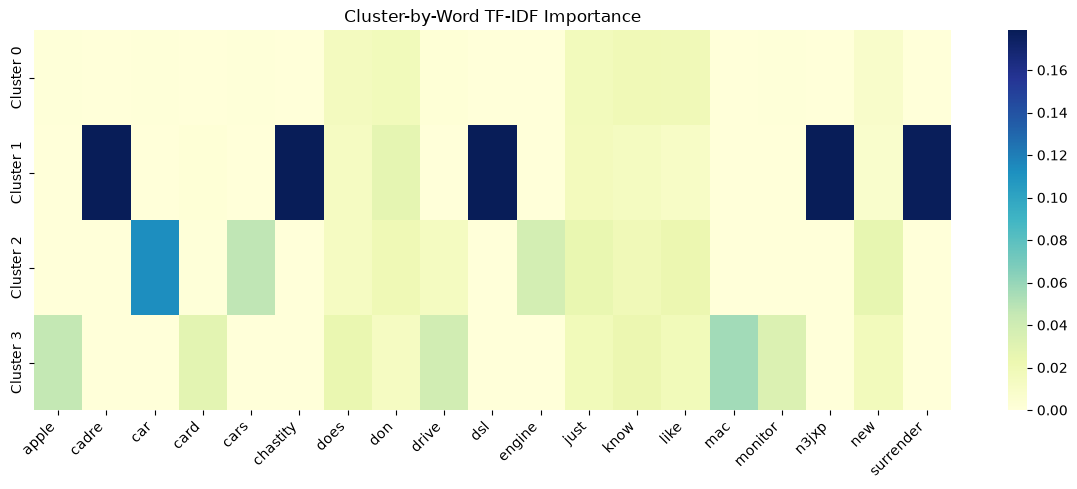

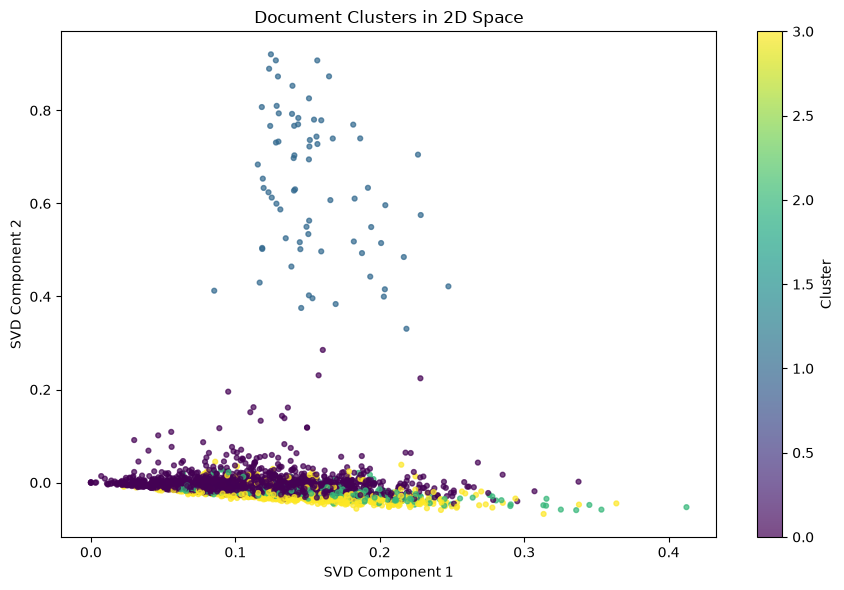

In [6]:
if X_tfidf is not None:
    # TODO 3.1: Fit K-Means
    kmeans = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=10
    )

    df["cluster"] = kmeans.fit_predict(X_tfidf)

    # TODO 3.2: Show the top 8 words for each cluster
    feature_names = tfidf_vec.get_feature_names_out()

    for cluster_id, centroid in enumerate(kmeans.cluster_centers_):
        top_indices = centroid.argsort()[-8:][::-1]
        top_terms = feature_names[top_indices]

        print(f"Cluster {cluster_id} top words:")
        print(", ".join(top_terms))
        print()

    # Heatmap using the top 5 words from each cluster
    top5_indices = set()

    for centroid in kmeans.cluster_centers_:
        top5_indices.update(centroid.argsort()[-5:])

    top5_indices = sorted(top5_indices)
    heatmap_words = feature_names[top5_indices]
    heatmap_values = kmeans.cluster_centers_[:, top5_indices]

    plt.figure(figsize=(12, 5))
    sns.heatmap(
        heatmap_values,
        xticklabels=heatmap_words,
        yticklabels=[f"Cluster {i}" for i in range(4)],
        cmap="YlGnBu"
    )
    plt.title("Cluster-by-Word TF-IDF Importance")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig("cluster_heatmap.png", dpi=150)
    plt.show()

    # TODO 3.3: Project the documents into two dimensions
    svd = TruncatedSVD(n_components=2, random_state=42)
    X_2d = svd.fit_transform(X_tfidf)

    plt.figure(figsize=(9, 6))
    scatter = plt.scatter(
        X_2d[:, 0],
        X_2d[:, 1],
        c=df["cluster"],
        cmap="viridis",
        s=12,
        alpha=0.7
    )
    plt.xlabel("SVD Component 1")
    plt.ylabel("SVD Component 2")
    plt.title("Document Clusters in 2D Space")
    plt.colorbar(scatter, label="Cluster")
    plt.tight_layout()
    plt.savefig("spatial_mapping.png", dpi=150)
    plt.show()

In [11]:
custom_stopwords = [
    "know", "like", "just", "think",
    "does", "use", "thanks"
]

all_stopwords = set(stopwords.words("english"))
all_stopwords.update(custom_stopwords)

clean_tfidf_vec = TfidfVectorizer(
    stop_words=list(all_stopwords),
    max_features=4000,
    min_df=5,
    max_df=0.5,
    token_pattern=r"\b[a-zA-Z]{3,}\b"
)

X_clean_tfidf = clean_tfidf_vec.fit_transform(df["text"])

clean_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clean_clusters = clean_kmeans.fit_predict(X_clean_tfidf)

# Keep the cleaned cluster assignments separately
df["clean_cluster"] = clean_clusters

clean_features = clean_tfidf_vec.get_feature_names_out()

print("Cleaned cluster keywords:")
for i, centroid in enumerate(clean_kmeans.cluster_centers_):
    top_idx = centroid.argsort()[-8:][::-1]
    print(f"Cluster {i}:", ", ".join(clean_features[top_idx]))


# CHALLENGE 2: Compare clusters with true categories

hardware_labels = [
    "sci.electronics",
    "comp.sys.mac.hardware"
]

for label in hardware_labels:
    print(f"\n--- {label} posts assigned to Cluster 0 ---")

    examples = df[
        (df["true_label"] == label) &
        (df["cluster"] == 0)
    ]["text"].head(3)

    for i, post in enumerate(examples, start=1):
        print(f"\nExample {i}:")
        print(post[:700])

bigram_vec = TfidfVectorizer(
    stop_words=list(all_stopwords),
    max_features=4000,
    min_df=5,
    max_df=0.5,
    token_pattern=r"\b[a-zA-Z]{3,}\b",
    ngram_range=(1, 2)
)

X_bigram = bigram_vec.fit_transform(df["text"])

bigram_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["bigram_cluster"] = bigram_kmeans.fit_predict(X_bigram)

display(pd.crosstab(df["true_label"], df["bigram_cluster"]))

print("\nTrue categories versus clusters:")
display(pd.crosstab(df["true_label"], df["cluster"]))


# CHALLENGE 3: Compare long and short document norms

document_lengths = df["text"].str.len()

long_idx = document_lengths.idxmax()
short_idx = document_lengths.idxmin()

print("\nLongest post length:", document_lengths.loc[long_idx])
print("Shortest post length:", document_lengths.loc[short_idx])

for name, matrix in [("BoW", X_bow), ("TF-IDF", X_tfidf)]:
    long_norm = np.linalg.norm(matrix[long_idx].toarray().ravel())
    short_norm = np.linalg.norm(matrix[short_idx].toarray().ravel())

    print(f"\n{name}:")
    print("Longest post norm:", long_norm)
    print("Shortest post norm:", short_norm)


# CHALLENGE 4: Explain one document

def explain_document(doc_id, matrix, vectorizer, top_n=5):
    """
    Return the top_n non-zero TF-IDF terms and their weights
    for a document identified by its row index.
    """
    if doc_id < 0 or doc_id >= matrix.shape[0]:
        raise IndexError("Document index is outside the dataset.")

    row = matrix[doc_id].toarray().ravel()
    feature_names = vectorizer.get_feature_names_out()

    nonzero_indices = np.flatnonzero(row)
    ranked_indices = nonzero_indices[
        np.argsort(row[nonzero_indices])[::-1]
    ][:top_n]

    result = [
        (feature_names[i], float(row[i]))
        for i in ranked_indices
    ]

    print(f"Top TF-IDF terms for document {doc_id}:")
    for term, weight in result:
        print(f"{term}: {weight:.6f}")

    return result


explanation = explain_document(
    doc_id=412,
    matrix=X_tfidf,
    vectorizer=tfidf_vec,
    top_n=5
)

Cleaned cluster keywords:
Cluster 0: geb, pitt, cadre, dsl, chastity, intellect, shameful, surrender
Cluster 1: would, one, anyone, get, also, could, good, much
Cluster 2: car, cars, engine, new, one, would, oil, ford
Cluster 3: mac, apple, drive, monitor, card, would, get, scsi

--- sci.electronics posts assigned to Cluster 0 ---

Example 1:
If you want slow LED flash rates, adjustable by switches (or by a
4066/4016 digitally controlled switch), I suggest looking at a 555
oscillator chip. They cost ~$1 at Radio Shack (much cheaper in
quantity at quality places), and you will be able to find good info
about simple circuits in a 555 oscialltor notebook (I think Forest
Mims has one at Radio Shack). You'll have to toy with
resistor/capacitor values OR you can use your head with a little math
to get the right frequencies. Any engineer worth his salt, can make a
555 osciallator... It's in the book, and left up to you to see (I hate
doing ASCII circuit graphics). The 555 can accurately go fr

bigram_cluster,0,1,2,3
true_label,,,,
comp.sys.mac.hardware,583,0,326,1
rec.autos,0,0,407,498
sci.electronics,36,0,885,19
sci.med,1,71,876,0



True categories versus clusters:


cluster,0,1,2,3
true_label,,,,
comp.sys.mac.hardware,269,0,2,639
rec.autos,396,0,507,2
sci.electronics,860,0,20,60
sci.med,875,71,0,2



Longest post length: 72161
Shortest post length: 52

BoW:
Longest post norm: 276.24083695210595
Shortest post norm: 2.0

TF-IDF:
Longest post norm: 1.0000000000000016
Shortest post norm: 0.9999999999999998
Top TF-IDF terms for document 412:
discussion: 0.452421
feel: 0.398890
days: 0.385506
need: 0.288483
meant: 0.266672
